In [145]:
import numpy as np
from sympy import *

import torch
# from torch import nn
from torch.nn.parameter import Parameter
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init as init

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

In [146]:
torch.rand(10) * 0.5

tensor([0.2569, 0.1339, 0.2280, 0.2490, 0.4133, 0.4615, 0.4084, 0.4578, 0.1651,
        0.3901])

In [147]:
# t, delta, omega = symbols("t delta omega")
t = Symbol("t", positive=True)

m = 1
mu = 5
k = 500

delta = mu/(2*m)
w0 = sqrt(k)
w = sqrt(w0**2 - delta**2)

phi = tan(-delta/w)**(-1)
A = 1/(2 * cos(phi))

display(A)

ODE = exp(-delta*t)*(2*A*cos(phi + w*t))
display(ODE.simplify())

-0.595470930409999

-1.19094186082*exp(-2.5*t)*cos(22.220486043289*t - 8.85065980104099)

In [148]:
n_train = 10

times_train = (np.random.rand(n_train) * 0.5).astype("float32")
D_train = (np.array([ODE.subs(t, time) for time in times_train])).astype("float32")
print(times_train)
print(D_train, "\n")

[0.00407587 0.44549614 0.03989374 0.35802886 0.3725551  0.47988373
 0.44991702 0.35974705 0.2977757  0.14067875]
[ 0.9278995  -0.19507535  0.11856499 -0.30434084 -0.39446816  0.08591484
 -0.15912995 -0.31724533  0.34824193 -0.71052456] 



In [149]:
simple_model = torch.nn.Sequential(
    # input layer with 1 input
    torch.nn.Linear(1, 10),
    torch.nn.Tanh(),
    # hidden layer
    torch.nn.Linear(10, 1)
)

print(simple_model)
net = simple_model

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Tanh()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


In [150]:
# num_features = 1
# num_l1 = 10
# num_out = 1

# class Net(nn.Module):

#     def __init__(self, num_features, num_hidden, num_output):
#         super(Net, self).__init__()  

#         # self.do = nn.Dropout(0.1)
#         # self.bn = nn.BatchNorm1d(num_features)
#         # input layer
#         self.W_1 = Parameter(init.kaiming_normal_(torch.Tensor(num_hidden, num_features)))
#         self.b_1 = Parameter(init.constant_(torch.Tensor(num_hidden), 0))
#         # hidden layer
#         self.W_2 = Parameter(init.xavier_normal_(torch.Tensor(num_hidden, num_hidden)))
#         self.b_2 = Parameter(init.constant_(torch.Tensor(num_hidden), 0))
#         # define activation function in constructor
#         self.activation = torch.nn.Tanh()

#     def forward(self, x):
#         x = self.bn(x)
#         x = F.linear(x, self.W_1, self.b_1)
#         x = self.activation(x)
#         x = F.linear(x, self.W_2, self.b_2)
#         return x

# net = Net(num_features, num_l1, num_out)

In [151]:
optimizer = optim.SGD(net.parameters(), lr=0.01)
criterion = torch.nn.MSELoss()

In [ ]:
# loss_fn = torch.nn.MSELoss(reduction='sum')
# model = simple_model

# x_train = torch.from_numpy(times_train)
# x_val = torch.from_numpy(times_val)
# target_train = torch.from_numpy(D_train)
# target_val = torch.from_numpy(D_val)

# learning_rate = 1e-4
# for t in range(500):
#     # Forward pass: compute predicted y by passing x to the model. Module objects
#     # override the __call__ operator so you can call them like functions. When
#     # doing so you pass a Tensor of input data to the Module and it produces
#     # a Tensor of output data.
#     for x, y in zip(x_train, target_train):
#         x = x.reshape(1,1)
#         y = y.reshape(1,1)
#         y_pred = model(x)

#         # Compute and print loss. We pass Tensors containing the predicted and true
#         # values of y, and the loss function returns a Tensor containing the
#         # loss.
#         loss = loss_fn(y_pred, y)
#         print(t, loss.item())

#         # Zero the gradients before running the backward pass.
#         model.zero_grad()

#         # Backward pass: compute gradient of the loss with respect to all the learnable
#         # parameters of the model. Internally, the parameters of each Module are stored
#         # in Tensors with requires_grad=True, so this call will compute gradients for
#         # all learnable parameters in the model.
#         loss.backward()

#         # Update the weights using gradient descent. Each parameter is a Tensor, so
#         # we can access its gradients like we did before.
#         with torch.no_grad():
#             for param in model.parameters():
#                 param -= learning_rate * param.grad

Epoch  1 : Train Loss 0.017582
Epoch 11 : Train Loss 0.017513
Epoch 21 : Train Loss 0.017446
Epoch 31 : Train Loss 0.017381
Epoch 41 : Train Loss 0.017319
Epoch 51 : Train Loss 0.017259
Epoch 61 : Train Loss 0.017200
Epoch 71 : Train Loss 0.017144
Epoch 81 : Train Loss 0.017089
Epoch 91 : Train Loss 0.017036


(Text(0.5, 0, 'Updates'), Text(0, 0.5, 'Loss'))

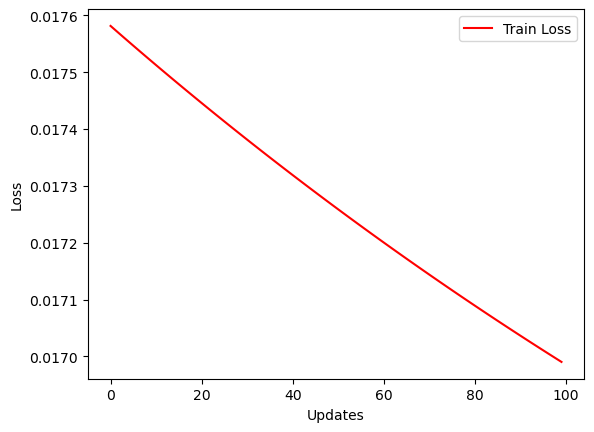

In [153]:
# we could have done this ourselves,
# but we should be aware of sklearn and its tools
from sklearn.metrics import accuracy_score

# changing data to tensors
x_train = torch.from_numpy(times_train).reshape(10,1)
target_train = torch.from_numpy(D_train).reshape(10,1)

# setting hyperparameters and gettings epoch sizes
batch_size = 10
num_epochs = 100
num_samples_train = len(x_train)
num_batches_train = num_samples_train // batch_size
# num_samples_valid = len(target_val)
# num_batches_valid = num_samples_valid // batch_size

# setting up lists for handling loss/accuracy
train_acc, train_loss = [], []
# valid_acc, valid_loss = [], []
test_acc, test_loss = [], []
cur_loss = 0
losses = []

get_slice = lambda i, size: range(i * size, (i + 1) * size)

for epoch in range(num_epochs):
    # Forward -> Backprob -> Update params
    ## Train
    cur_loss = 0
    net.train()
    for i in range(num_batches_train):
        optimizer.zero_grad()
        slce = get_slice(i, batch_size)
        output = net(x_train[slce])
        
        # compute gradients given loss
        target_batch = target_train[slce]
        batch_loss = criterion(output, target_batch)
        batch_loss.backward()
        optimizer.step()
        
        cur_loss += batch_loss   
    losses.append(cur_loss / batch_size)

    net.eval()
    ### Evaluate training
    train_preds, train_targs = [], []
    for i in range(num_batches_train):
        slce = get_slice(i, batch_size)
        output = net(x_train[slce])

        preds = output
        # preds = torch.max(output, 1)[1]
        
        train_targs += list(target_train[slce].numpy())
        train_preds += list(preds.data.numpy())
        

    # train_acc_cur = accuracy_score(train_targs, train_preds)
    # train_acc_cur = 
    
    # train_acc.append(train_acc_cur)
    
    if epoch % 10 == 0:
        print("Epoch %2i : Train Loss %f" % (
                epoch+1, losses[-1]))

losses_plot = [loss.detach().numpy() for loss in losses]
epoch = np.arange(epoch + 1)
plt.figure()
plt.plot(epoch, losses_plot, 'r')
plt.legend(['Train Loss'])
plt.xlabel('Updates'), plt.ylabel('Loss')

In [158]:
t = symbols("t", positive=True)
n_val = 10

# create validation data
# times_val = (np.random.rand(n_val) * 0.5).astype("float32")
times_val = np.arange(0, 1, 1/n_val).astype("float32")
D_val = (np.array([ODE.subs(t, time) for time in times_val])).astype("float32")
print(times_val)
print(D_val)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
[ 1.         -0.8727199   0.21748395  0.3239848  -0.43781444  0.21687381
  0.06077737 -0.18892623  0.14151908 -0.01903148]


(Text(0.5, 0, 't'), Text(0, 0.5, 'Loss'))

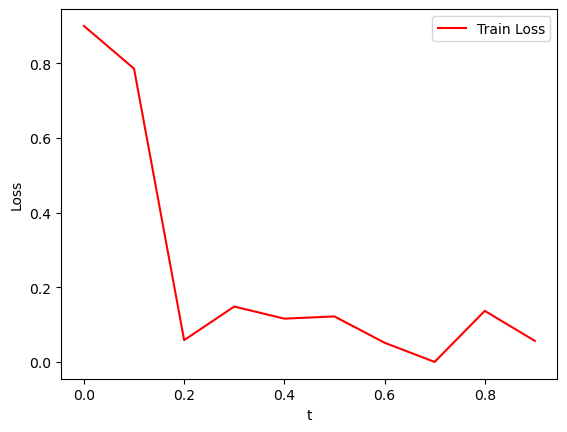

In [168]:
x_val = torch.from_numpy(times_val).reshape(len(times_val),1)
target_val = torch.from_numpy(D_val).reshape(len(D_val),1)

val_loss = []
for i in range(len(times_val)):
    output = net(x_val[i])

    # compute gradients given loss
    target_batch = target_val[i]
    batch_loss = criterion(output, target_batch)
    val_loss.append(batch_loss)

plot_loss = [loss.detach().numpy() for loss in val_loss]
plt.figure()
plt.plot(x_val, plot_loss, 'r')
plt.legend(['Train Loss'])
plt.xlabel('t'), plt.ylabel('Loss')

In [ ]:
# optimizer.zero_grad()
slce = get_slice(0, 10)
output = net(x_train[slce])

# compute gradients given loss
target_batch = target_train[slce]
batch_loss = criterion(output, target_batch)
# batch_loss.backward()
# optimizer.step()

print(batch_loss)

tensor(0.1909, grad_fn=<MseLossBackward0>)


In [ ]:
# val_preds, val_targs = [], []

# # for i in range(num_batches_valid):
# #     slce = get_slice(i, batch_size)
    
# #     output = net(x_val[slce])
# #     # preds = torch.max(output, 1)[1]
# #     val_targs += list(target_val[slce].numpy())
# #     val_preds += list(preds.data.numpy())

# for i in range(len(x_val)):
#     output = net(x_val[i])
#     val_preds.append(output)
    

# # for val in range(x_val):
# #     output = net(val)
# #     val_preds.append(output)

# val_preds, target_val